# Análise complementar - Regressão

O problema de regressão consiste em estimar Employability_Score a partir das variáveis acadêmicas e de habilidades selecionadas. São examinadas a distribuição do alvo, suas associações com os atributos explicativos e as limitações dessas relações para modelagem.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
ROOT=Path('..'); DATA=ROOT/'data/processed'; FIG=ROOT/'reports/figures'; TABLE=ROOT/'reports/tables'
FIG.mkdir(parents=True,exist_ok=True);TABLE.mkdir(parents=True,exist_ok=True)
df=pd.read_csv(DATA/'dataset_regression.csv'); target='Employability_Score'
print(df.shape); display(df[target].describe().to_frame().T)

(50000, 23)


,count,mean,std,min,25%,50%,75%,max
Employability_Score,50000.0,213.991394,26.824224,82.3,197.35,217.25,233.6,279.05


## 1. Distribuição e valores atípicos do target

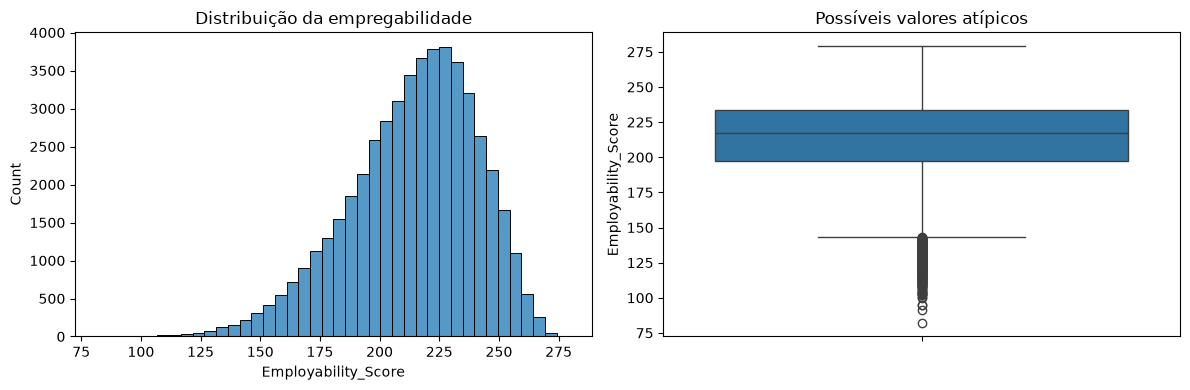

Fora dos limites IQR: 545


In [2]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.histplot(df[target],bins=40,ax=ax[0],color="C0");ax[0].set_title('Distribuição da empregabilidade')
sns.boxplot(y=df[target],ax=ax[1],color="C0");ax[1].set_title('Possíveis valores atípicos')
plt.tight_layout();plt.savefig(FIG/'regression_target_distribution.png',dpi=160);plt.show()
q1,q3=df[target].quantile([.25,.75]);iqr=q3-q1
print('Fora dos limites IQR:',int(((df[target]<q1-1.5*iqr)|(df[target]>q3+1.5*iqr)).sum()))

## 2. Correlações numéricas e gráficos de relações

,Pearson
Interview_Score,0.844578
Programming_Skill,0.814310
Resume_Score,0.790519
Internships,0.789657
Problem_Solving,0.764074
Projects_Completed,0.752465
CGPA,0.601362
Communication_Skills,0.556664
Attendance_Percentage,0.403592
Hackathons,0.364893


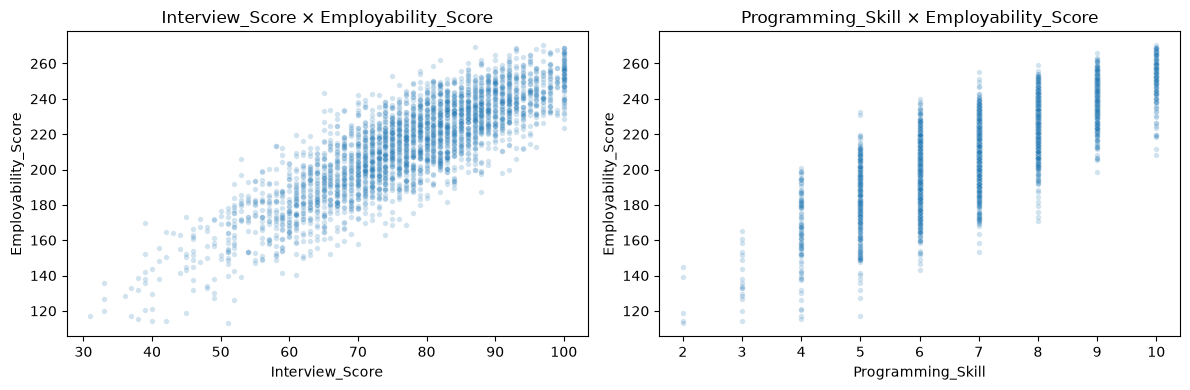

In [3]:
cor=df.select_dtypes(include='number').corr(numeric_only=True)[target].drop(target).sort_values(key=abs,ascending=False)
display(cor.to_frame('Pearson').head(15))
cor.to_csv(TABLE/'regression_correlations.csv',header=['pearson'])
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,col in zip(axes,cor.index[:2]):
    sns.scatterplot(data=df.sample(min(3000,len(df)),random_state=42),x=col,y=target,ax=ax,alpha=.2,s=15,color="C0")
    ax.set_title(f'{col} × {target}')
plt.tight_layout();plt.savefig(FIG/'regression_relationships.png',dpi=160);plt.show()

## 3. Seleção e recomendações

O alvo tem variação contínua e é apropriado para regressão. As variáveis mais correlacionadas serão listadas no resultado da célula anterior, sem presumir relações causais.

Desafios: possível redundância entre notas e habilidades, não linearidade e valores atípicos.